# Feature Scaling

In [1]:
import numpy as np 
import pandas as pd

df = pd.read_csv("./data/06_Feature_Engineering.csv")

In [2]:
df.shape

(57130, 102)

### Explicit feature groups

# Frequency-encoded categorical features
frequency_features = [
    'district_name',
    'block_tehsil_name',
    'village_name'
]

# Original binary features
original_binary_features = [
    'scheme_type',
    'located_in_command_area',
    'only_recharge_ground_water',
    'drinking_water_purpose'
]

# One-hot encoded feature prefixes
one_hot_prefixes = [
    'water_distribution_method_',
    'energy_source_',
    'well_type_',
    'ownership_',
    'lifting_device_type_',
    'social_status_',
    'gender_',
    'scheme_status_',
    'captured_in_previous_census_',
    'under_utilised_selection_',
    'finance_source_'
]

one_hot_features = [
    col for col in df.columns
    if any(col.startswith(prefix) for prefix in one_hot_prefixes)
]

# Ordinal features
ordinal_features = ['commissioning_year']

# Categorical-label features
categorical_label_features = ['geographic_cluster']

# Continuous numerical candidates
continuous_features = [
    'latitude',
    'longitude',
    'scheme_depth',
    'scheme_diameter',
    'nearest_scheme_distance',
    'horse_power_of_lifting_device',
    'culturable_command_area',
    'culturable_command_area_log'
]

# Verify that all identified columns exist
feature_groups = {
    'Frequency Encoded': frequency_features,
    'Original Binary': original_binary_features,
    'One-Hot Encoded': one_hot_features,
    'Ordinal': ordinal_features,
    'Categorical Label': categorical_label_features,
    'Continuous Candidates': continuous_features
}

for group, columns in feature_groups.items():
    missing = [col for col in columns if col not in df.columns]
    print(f"\n{group}: {len(columns)}")
    if missing:
        print("Missing columns:", missing)

print("\nTotal identified features:",
      sum(len(cols) for cols in feature_groups.values())) Data

In [3]:
import pandas as pd
import numpy as np

target = 'construction_cost'

ignored_columns = [
    'Unnamed: 0',
    'Total_Outlier_Flags',
    'total_owners_holding'
]

# Exclude IPC/IPU-related columns
ipc_ipu_columns = [
    col for col in df.columns
    if col.lower().startswith(('ipc_', 'ipu_'))
]

# Exclude target and ignored columns
excluded_columns = set(
    [target] + ignored_columns + ipc_ipu_columns
)

# Remaining predictor columns
predictor_columns = [
    col for col in df.columns
    if col not in excluded_columns
]

# Identify binary features
binary_features = [
    col for col in predictor_columns
    if df[col].dropna().nunique() == 2
    and set(df[col].dropna().unique()).issubset({0, 1})
]

# Identify one-hot encoded features
one_hot_features = [
    col for col in binary_features
    if '_' in col
]

# Identify ordinal features
ordinal_features = ['commissioning_year']

# Identify categorical-label features
categorical_label_features = ['geographic_cluster']

# Remove already classified features
classified_features = set(
    binary_features +
    ordinal_features +
    categorical_label_features
)

# Identify continuous numerical predictors
continuous_features = [
    col for col in predictor_columns
    if pd.api.types.is_numeric_dtype(df[col])
    and col not in classified_features
]

# Display results
print("=" * 60)
print("FEATURE CLASSIFICATION")
print("=" * 60)

print("\n1. Continuous Numerical Features:")
print(continuous_features)
print("Count:", len(continuous_features))

print("\n2. Binary Features:")
print(binary_features)
print("Count:", len(binary_features))

print("\n3. One-Hot Encoded Features:")
print(one_hot_features)
print("Count:", len(one_hot_features))

print("\n4. Ordinal Features:")
print(ordinal_features)

print("\n5. Categorical-Label Features:")
print(categorical_label_features)

print("\n6. Excluded Features:")
print(sorted(excluded_columns))

print("\nTotal Predictor Features:", len(predictor_columns))

FEATURE CLASSIFICATION

1. Continuous Numerical Features:
['district_name', 'block_tehsil_name', 'village_name', 'latitude', 'longitude', 'scheme_depth', 'scheme_diameter', 'nearest_scheme_distance', 'horse_power_of_lifting_device', 'culturable_command_area', 'culturable_command_area_log']
Count: 11

2. Binary Features:
['scheme_type', 'located_in_command_area', 'only_recharge_ground_water', 'drinking_water_purpose', 'water_distribution_method_Drip', 'water_distribution_method_Not applicable', 'water_distribution_method_Open Water Channel (lined / Pucca)', 'water_distribution_method_Open Water Channel (unlined / Kutcha)', 'water_distribution_method_Other', 'water_distribution_method_Sprinkler', 'water_distribution_method_Surface pipe', 'water_distribution_method_Under ground pipe', 'energy_source_Diesel', 'energy_source_Electric', 'energy_source_Manual/animal', 'energy_source_Natural', 'energy_source_Not applicable', 'energy_source_Others', 'energy_source_Solar', 'energy_source_Wind Mi

In [4]:
# Explicit feature groups

# Frequency-encoded categorical features
frequency_features = [
    'district_name',
    'block_tehsil_name',
    'village_name'
]

# Original binary features
original_binary_features = [
    'scheme_type',
    'located_in_command_area',
    'only_recharge_ground_water',
    'drinking_water_purpose'
]

# One-hot encoded feature prefixes
one_hot_prefixes = [
    'water_distribution_method_',
    'energy_source_',
    'well_type_',
    'ownership_',
    'lifting_device_type_',
    'social_status_',
    'gender_',
    'scheme_status_',
    'captured_in_previous_census_',
    'under_utilised_selection_',
    'finance_source_'
]

one_hot_features = [
    col for col in df.columns
    if any(col.startswith(prefix) for prefix in one_hot_prefixes)
]

# Ordinal features
ordinal_features = ['commissioning_year']

# Categorical-label features
categorical_label_features = ['geographic_cluster']

# Continuous numerical candidates
continuous_features = [
    'latitude',
    'longitude',
    'scheme_depth',
    'scheme_diameter',
    'nearest_scheme_distance',
    'horse_power_of_lifting_device',
    'culturable_command_area',
    'culturable_command_area_log'
]

# Verify that all identified columns exist
feature_groups = {
    'Frequency Encoded': frequency_features,
    'Original Binary': original_binary_features,
    'One-Hot Encoded': one_hot_features,
    'Ordinal': ordinal_features,
    'Categorical Label': categorical_label_features,
    'Continuous Candidates': continuous_features
}

for group, columns in feature_groups.items():
    missing = [col for col in columns if col not in df.columns]
    print(f"\n{group}: {len(columns)}")
    if missing:
        print("Missing columns:", missing)

print("\nTotal identified features:",
      sum(len(cols) for cols in feature_groups.values()))


Frequency Encoded: 3

Original Binary: 4

One-Hot Encoded: 72

Ordinal: 1

Categorical Label: 1

Continuous Candidates: 8

Total identified features: 89


## Analyze Feature Distributions

In [6]:
# Statistical analysis of continuous numerical features

distribution_stats = df[continuous_features].describe().T

distribution_stats['skewness'] = df[continuous_features].skew()
distribution_stats['variance'] = df[continuous_features].var()

distribution_stats = distribution_stats[
    ['min', 'max', 'mean', 'std', 'variance', 'skewness']
]

display(distribution_stats.round(3))

,min,max,mean,std,variance,skewness
latitude,24.270,27.973,26.314,0.422,0.178,-0.415
longitude,89.703,95.889,91.458,1.448,2.096,0.969
scheme_depth,0.030,60.000,26.303,12.176,148.253,1.071
scheme_diameter,0.010,231.956,77.085,53.935,2908.944,0.168
nearest_scheme_distance,0.010,600.000,201.298,166.033,27566.975,0.943
horse_power_of_lifting_device,0.000,9.000,3.621,1.710,2.925,0.283
culturable_command_area,0.000,750.000,3.101,7.368,54.290,44.532
culturable_command_area_log,0.000,6.621,1.175,0.571,0.326,1.166


### Visualize Feature Distributions

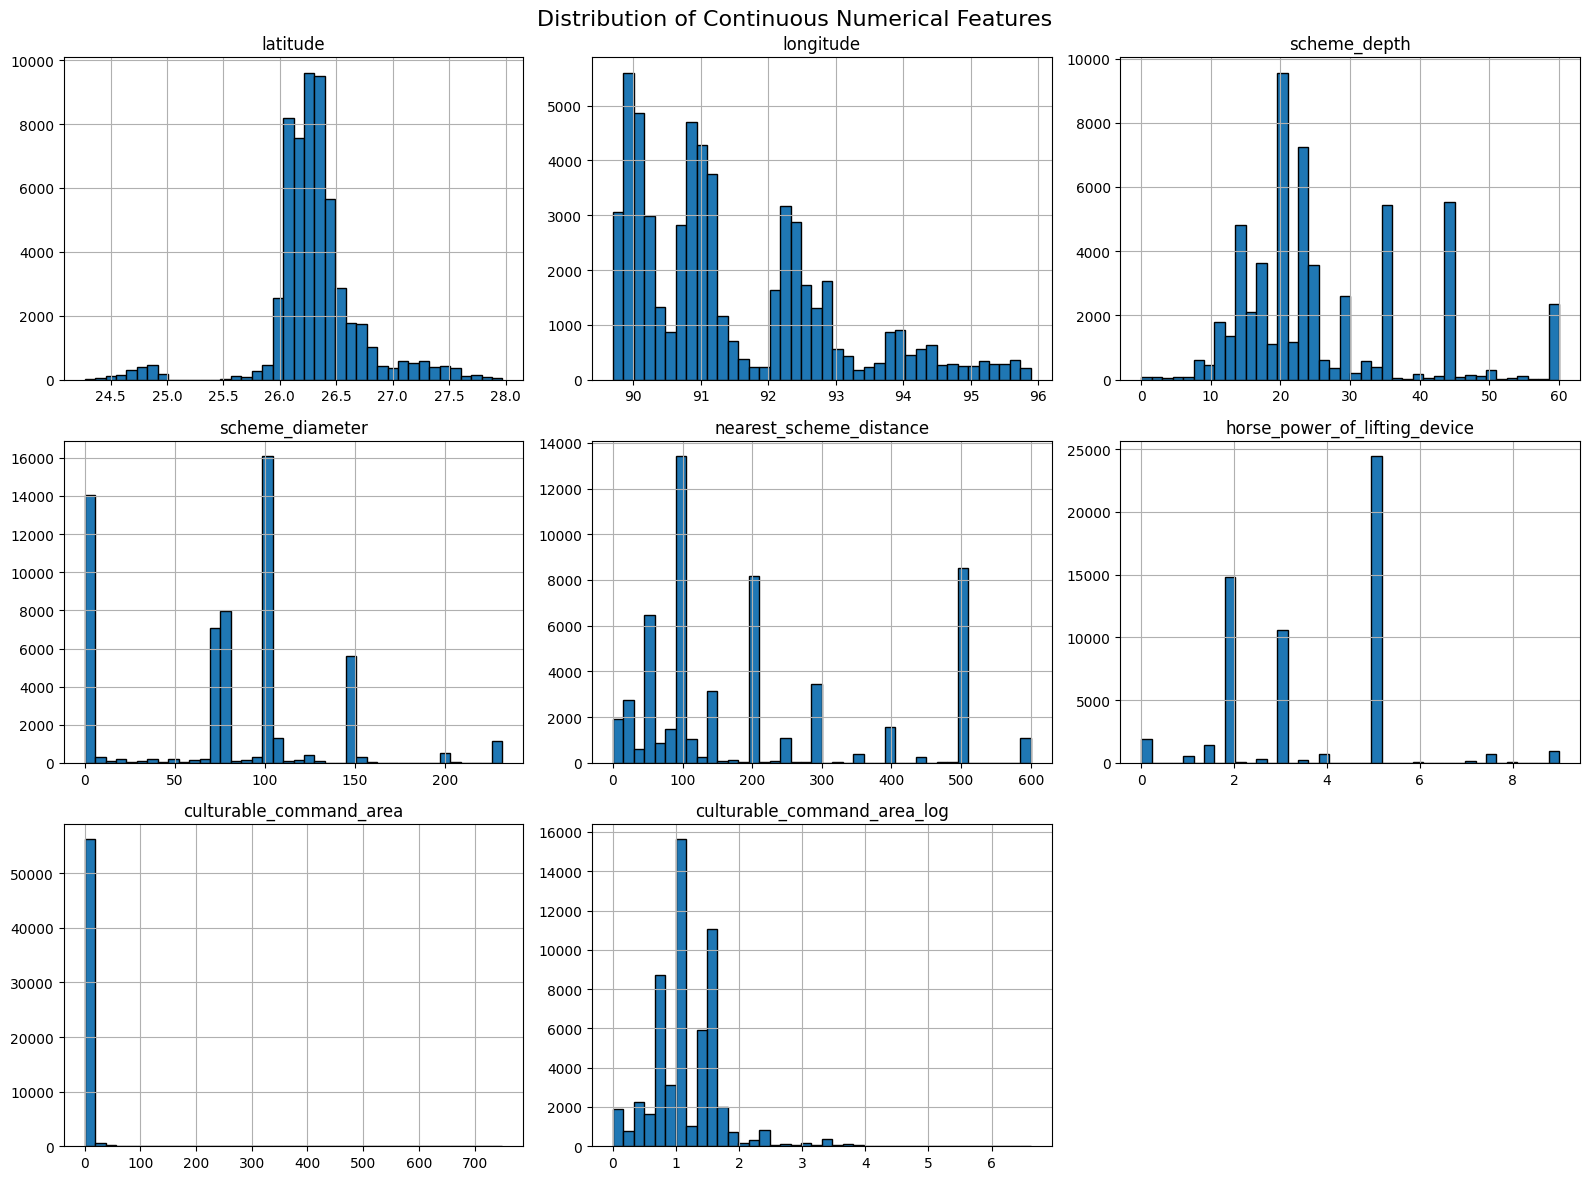

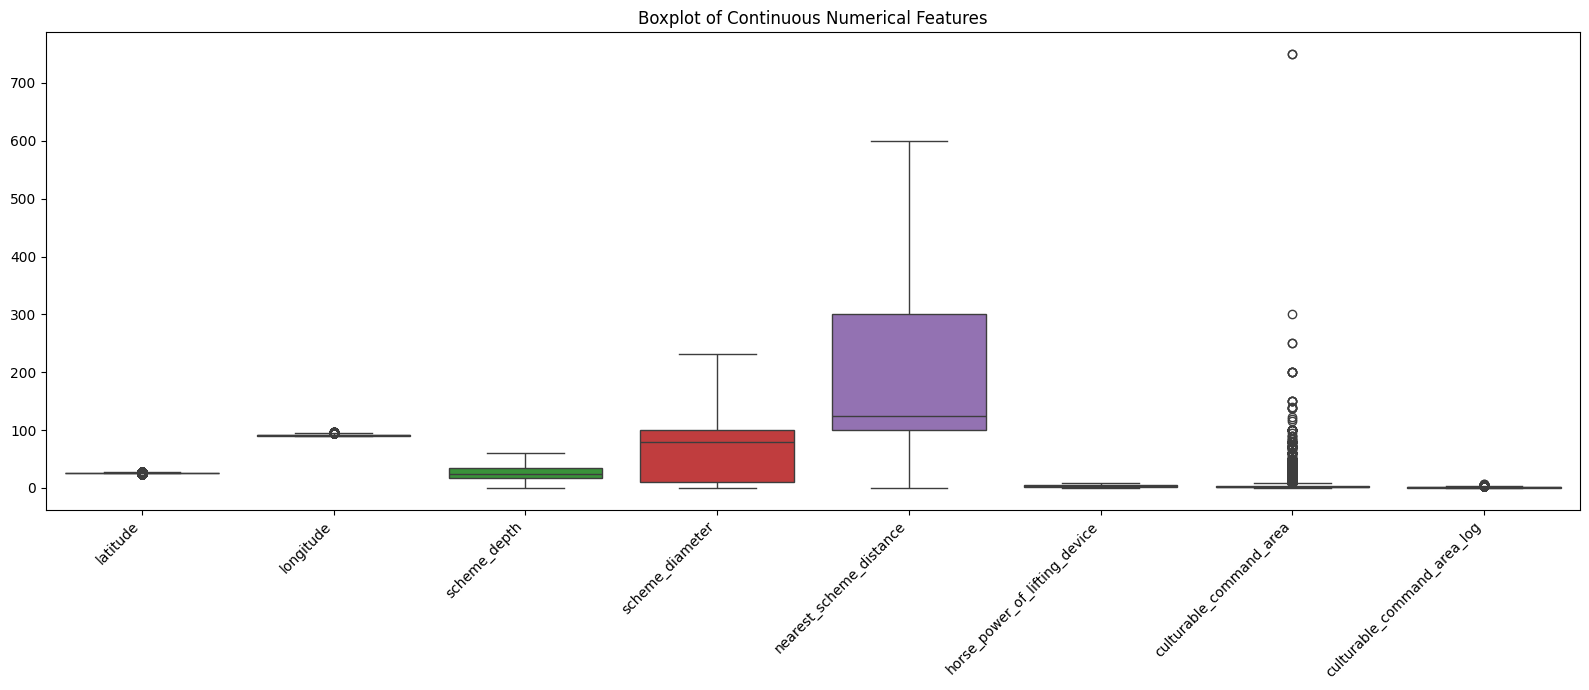

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Histograms
df[continuous_features].hist(
    figsize=(16, 12),
    bins=40,
    edgecolor='black'
)

plt.suptitle('Distribution of Continuous Numerical Features', fontsize=16)
plt.tight_layout()
plt.show()

# Boxplots
plt.figure(figsize=(16, 7))

sns.boxplot(data=df[continuous_features])

plt.title('Boxplot of Continuous Numerical Features')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## Compare Feature Scaling Methods

In [8]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

# Compare scaling methods on continuous candidates
scalers = {
    'StandardScaler': StandardScaler(),
    'MinMaxScaler': MinMaxScaler(),
    'RobustScaler': RobustScaler()
}

comparison_results = []

for scaler_name, scaler in scalers.items():

    scaled_data = scaler.fit_transform(df[continuous_features])

    scaled_df = pd.DataFrame(
        scaled_data,
        columns=continuous_features
    )

    for col in continuous_features:
        comparison_results.append({
            'Scaler': scaler_name,
            'Feature': col,
            'Mean': scaled_df[col].mean(),
            'Std': scaled_df[col].std(),
            'Min': scaled_df[col].min(),
            'Max': scaled_df[col].max(),
            'Median': scaled_df[col].median(),
            'IQR': (
                scaled_df[col].quantile(0.75)
                - scaled_df[col].quantile(0.25)
            )
        })

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df.round(3))

,Scaler,Feature,Mean,Std,Min,Max,Median,IQR
0,StandardScaler,latitude,-0.000,1.000,-4.845,3.929,-0.063,0.729
1,StandardScaler,longitude,-0.000,1.000,-1.212,3.061,-0.296,1.516
2,StandardScaler,scheme_depth,-0.000,1.000,-2.158,2.768,-0.189,1.396
3,StandardScaler,scheme_diameter,0.000,1.000,-1.429,2.871,0.054,1.669
4,StandardScaler,nearest_scheme_distance,0.000,1.000,-1.212,2.401,-0.460,1.205
5,StandardScaler,horse_power_of_lifting_device,0.000,1.000,-2.118,3.145,-0.363,1.754
6,StandardScaler,culturable_command_area,0.000,1.000,-0.421,101.369,-0.149,0.407
7,StandardScaler,culturable_command_area_log,-0.000,1.000,-2.060,9.546,-0.134,1.606
8,MinMaxScaler,latitude,0.552,0.114,0.000,1.000,0.545,0.083
9,MinMaxScaler,longitude,0.284,0.234,0.000,1.000,0.214,0.355


## Apply Feature Scaling

In [10]:
from sklearn.model_selection import train_test_split

# Separate target and predictors
X = df.drop(columns=['construction_cost'])
y = df['construction_cost'].copy()

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

print("\nTotal Records:",
      len(X_train) + len(X_test))

Training Features: (45704, 101)
Testing Features: (11426, 101)

Training Target: (45704,)
Testing Target: (11426,)

Total Records: 57130


### Fit RobustScaler on Training Data

In [13]:
from sklearn.preprocessing import RobustScaler

# Define selected scaling features
scaling_features = [
    'latitude',
    'longitude',
    'scheme_depth',
    'scheme_diameter',
    'nearest_scheme_distance',
    'horse_power_of_lifting_device',
    'culturable_command_area_log'
]

# Initialize scaler
scaler = RobustScaler()

# Preserve original datasets
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

# Fit on training data only
X_train_scaled[scaling_features] = scaler.fit_transform(
    X_train[scaling_features]
)

# Transform test data
X_test_scaled[scaling_features] = scaler.transform(
    X_test[scaling_features]
)

print("Scaling completed successfully!")

print("Training Shape:", X_train_scaled.shape)
print("Testing Shape:", X_test_scaled.shape)

print("\nScaled Features:")
print(scaling_features)

Scaling completed successfully!
Training Shape: (45704, 101)
Testing Shape: (11426, 101)

Scaled Features:
['latitude', 'longitude', 'scheme_depth', 'scheme_diameter', 'nearest_scheme_distance', 'horse_power_of_lifting_device', 'culturable_command_area_log']


## Verify Scaled Data

In [14]:
# Verify scaled training feature distributions

scaled_stats = X_train_scaled[scaling_features].describe().T

scaled_stats = scaled_stats[
    ['mean', 'std', 'min', 'max', '50%']
]

display(scaled_stats.round(4))

,mean,std,min,max,50%
latitude,0.0885,1.3730,-6.5653,5.4806,0.0
longitude,0.1960,0.6606,-0.6035,2.2126,0.0
scheme_depth,0.1363,0.7165,-1.4088,2.1176,0.0
scheme_diameter,-0.0317,0.6002,-0.8888,1.6884,0.0
nearest_scheme_distance,0.4058,0.8288,-0.6000,2.4000,0.0
horse_power_of_lifting_device,0.2069,0.5699,-1.0000,2.0000,0.0
culturable_command_area_log,0.0849,0.6213,-1.1990,5.0295,0.0


### Verify Target Variable Remains Unchanged

In [16]:
# Verify target variable integrity

print("=" * 50)
print("TARGET VARIABLE VERIFICATION")
print("=" * 50)

print("\nTarget Variable: construction_cost")

print("Training Target Unchanged:",
      y_train.equals(df.loc[y_train.index, 'construction_cost']))

print("Testing Target Unchanged:",
      y_test.equals(df.loc[y_test.index, 'construction_cost']))

print("\nTraining Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

print("\nTarget Data Type:", y_train.dtype)

TARGET VARIABLE VERIFICATION

Target Variable: construction_cost
Training Target Unchanged: True
Testing Target Unchanged: True

Training Target Shape: (45704,)
Testing Target Shape: (11426,)

Target Data Type: float64


### Verify Row Counts and Feature Preservation

In [17]:
print("=" * 55)
print("FINAL FEATURE SCALING VERIFICATION")
print("=" * 55)

# Row count verification
print("\n1. Row Counts")
print("Original Dataset:", len(df))
print("Training Dataset:", len(X_train_scaled))
print("Testing Dataset:", len(X_test_scaled))
print("Total Preserved:",
      len(X_train_scaled) + len(X_test_scaled) == len(df))

# Column verification
print("\n2. Feature Preservation")
print("Original Predictor Columns:", X.shape[1])
print("Training Columns:", X_train_scaled.shape[1])
print("Testing Columns:", X_test_scaled.shape[1])

print("All Columns Preserved:",
      list(X.columns) == list(X_train_scaled.columns) ==
      list(X_test_scaled.columns))

# Index verification
print("\n3. Index Verification")
print("Training-Test Overlap:",
      len(set(X_train_scaled.index) & set(X_test_scaled.index)))

# Non-scaled feature verification
non_scaled_features = [
    col for col in X.columns
    if col not in scaling_features
]

print("\n4. Non-Scaled Feature Preservation")
print(
    "Training Features Unchanged:",
    X_train[non_scaled_features].equals(
        X_train_scaled[non_scaled_features]
    )
)

print(
    "Testing Features Unchanged:",
    X_test[non_scaled_features].equals(
        X_test_scaled[non_scaled_features]
    )
)

FINAL FEATURE SCALING VERIFICATION

1. Row Counts
Original Dataset: 57130
Training Dataset: 45704
Testing Dataset: 11426
Total Preserved: True

2. Feature Preservation
Original Predictor Columns: 101
Training Columns: 101
Testing Columns: 101
All Columns Preserved: True

3. Index Verification
Training-Test Overlap: 0

4. Non-Scaled Feature Preservation
Training Features Unchanged: True
Testing Features Unchanged: True


# Save Dataset

In [18]:
df.to_csv("./data/07_Feature_Scaling.csv", index=False)